<a href="https://colab.research.google.com/github/pedrosampaiom2007-gif/Analise-de-dados-Airbnb-Rio/blob/main/notebooks/analise_precos_airbnb_rio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quanto custa uma noite no Rio? Análise de preços do Airbnb

Análise dos anúncios do Airbnb no Rio de Janeiro com Python e pandas: limpeza dos dados, tratamento de outliers e respostas para 6 perguntas.

**Fonte:** [Inside Airbnb](https://insideairbnb.com/get-the-data/), Rio de Janeiro (CC BY 4.0). Data da extração: 22/09/2026.

## Perguntas
1. Quais são os bairros mais caros e os mais baratos?
2. Quanto custa cada tipo de acomodação nos bairros mais procurados?
3. Superhosts cobram mais e são mais bem avaliados?
4. Quais são as comodidades mais comuns? Ter piscina deixa a diária mais cara?
5. Quantos anfitriões entraram no Airbnb a cada ano?
6. Quanto custa a diária média em dólar?

## Sumário
0. Configuração
1. Coleta dos dados
2. Entendimento inicial
3. Tratamento
4. Outliers
5. Transformações
6. Análises
7. Exportação
8. Conclusões

## 0. Configuração

In [484]:
# Importa as bibliotecas usadas no projeto.
# Por quê: pandas/numpy para tratar os dados, matplotlib/seaborn para os gráficos, requests para a API do Banco Central.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

# Mostra todas as colunas ao exibir um DataFrame (a base tem mais de 70 colunas).
pd.set_option('display.max_columns', None)

## 1. Coleta dos dados

Arquivo `listings.csv.gz` (anúncios) do Rio de Janeiro, lido direto da URL.

In [485]:
# Arquivo listings do RIO DE JANEIRO, extração de 22/09/2026 (insideairbnb.com/get-the-data).
# O pandas lê o .csv.gz direto do link, sem precisar baixar.
URL_LISTINGS = 'https://data.insideairbnb.com/brazil/rj/rio-de-janeiro/2026-09-22/data/listings.csv.gz'

In [486]:
# Colunas usadas na análise (as outras 60+ não são necessárias).
COLUNAS = [
    'id', 'name', 'host_id', 'host_since', 'host_response_rate', 'host_acceptance_rate',
    'host_is_superhost', 'host_identity_verified', 'host_listings_count',
    'neighbourhood_cleansed', 'latitude', 'longitude', 'property_type', 'room_type',
    'accommodates', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price',
    'minimum_nights', 'availability_365', 'number_of_reviews', 'first_review', 'last_review',
    'review_scores_rating', 'review_scores_location', 'review_scores_value', 'instant_bookable',
]

## 2. Entendimento inicial

Antes de mexer nos dados: quantas linhas, quais tipos, onde estão os nulos.

In [487]:
df=pd.read_csv(URL_LISTINGS,usecols=COLUNAS,sep=',')# lendo o arquivo

In [488]:
df.head() # Conhecendo a base de dados

,id,name,host_id,host_since,host_response_rate,host_acceptance_rate,host_is_superhost,host_listings_count,host_identity_verified,neighbourhood_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,availability_365,number_of_reviews,first_review,last_review,review_scores_rating,review_scores_location,review_scores_value,instant_bookable
0,17878,"Very Nice 2Br in Copacabana w. balcony, fast WiFi",68997,NaN,NaN,NaN,t,2,t,Copacabana,-22.96599,-43.17940,Entire condo,Entire home/apt,5,1 bath,2.0,2.0,"[""Dining table"", ""Dako stainless steel gas sto...",$513.00,1.0,194,359,2010-07-15,2026-09-13,4.72,4.78,4.68,NaN
1,25026,Beautiful Modern Decorated Studio in Copacabana,102840,NaN,NaN,NaN,t,1,t,Copacabana,-22.97649,-43.19122,Entire rental unit,Entire home/apt,3,1 bath,1.0,2.0,"[""Dining table"", ""Coffee"", ""Paid street parkin...",$422.00,2.0,200,333,2010-06-07,2026-09-20,4.77,4.86,4.66,NaN
2,35764,COPACABANA SEA BREEZE - RIO - 25 X Superhost,153691,NaN,NaN,NaN,t,1,t,Copacabana,-22.98107,-43.19136,Entire loft,Entire home/apt,2,1.5 baths,1.0,1.0,"[""Paid street parking off premises"", ""Coffee m...",$366.00,3.0,69,566,2010-10-03,2026-09-21,4.91,4.95,4.89,NaN
3,48305,Bright 6bed Penthouse Seconds from Beach,70933,NaN,NaN,NaN,t,5,t,Ipanema,-22.98591,-43.20302,Entire rental unit,Entire home/apt,13,7 baths,6.0,7.0,"[""Long term stays allowed"", ""Coffee maker"", ""H...","$3,761.43",5.0,225,186,2011-03-02,2026-09-07,4.77,4.95,4.60,NaN
4,48901,Extra large 4 bedrooms on AtlanticAve. Copacabana,222884,NaN,NaN,NaN,f,2,t,Copacabana,-22.96574,-43.17514,Entire rental unit,Entire home/apt,9,2.5 baths,4.0,5.0,"[""Dining table"", ""Long term stays allowed"", ""H...","$1,173.25",2.0,326,78,2015-08-01,2026-09-20,4.62,4.96,4.56,NaN


In [489]:
df.shape # Linhas x colunas

(48247, 29)

In [490]:
# Renomeando as colunas para o português

colunas_traduzidas = {
    'id': 'id',
    'name': 'nome',
    'host_id': 'anfitriao_id',
    'host_since': 'anfitriao_desde',
    'host_response_rate': 'taxa_resposta_anfitriao',
    'host_acceptance_rate': 'taxa_aceitacao_anfitriao',
    'host_is_superhost': 'anfitriao_superhost',
    'host_identity_verified': 'anfitriao_identidade_verificada',
    'host_listings_count': 'total_anuncios_anfitriao',
    'neighbourhood_cleansed': 'bairro',
    'latitude': 'latitude',
    'longitude': 'longitude',
    'property_type': 'tipo_propriedade',
    'room_type': 'tipo_quarto',
    'accommodates': 'acomoda',
    'bathrooms_text': 'banheiros_texto',
    'bedrooms': 'quartos',
    'beds': 'camas',
    'amenities': 'comodidades',
    'price': 'preco',
    'minimum_nights': 'minimo_noites',
    'availability_365': 'disponibilidade_365',
    'number_of_reviews': 'numero_avaliacoes',
    'first_review': 'primeira_avaliacao',
    'last_review': 'ultima_avaliacao',
    'review_scores_rating': 'nota_geral',
    'review_scores_location': 'nota_localizacao',
    'review_scores_value': 'nota_custo_beneficio',
    'instant_bookable': 'reserva_instantanea'
}

df.rename(columns=colunas_traduzidas, inplace=True)
display(df.head())

,id,nome,anfitriao_id,anfitriao_desde,taxa_resposta_anfitriao,taxa_aceitacao_anfitriao,anfitriao_superhost,total_anuncios_anfitriao,anfitriao_identidade_verificada,bairro,latitude,longitude,tipo_propriedade,tipo_quarto,acomoda,banheiros_texto,quartos,camas,comodidades,preco,minimo_noites,disponibilidade_365,numero_avaliacoes,primeira_avaliacao,ultima_avaliacao,nota_geral,nota_localizacao,nota_custo_beneficio,reserva_instantanea
0,17878,"Very Nice 2Br in Copacabana w. balcony, fast WiFi",68997,NaN,NaN,NaN,t,2,t,Copacabana,-22.96599,-43.17940,Entire condo,Entire home/apt,5,1 bath,2.0,2.0,"[""Dining table"", ""Dako stainless steel gas sto...",$513.00,1.0,194,359,2010-07-15,2026-09-13,4.72,4.78,4.68,NaN
1,25026,Beautiful Modern Decorated Studio in Copacabana,102840,NaN,NaN,NaN,t,1,t,Copacabana,-22.97649,-43.19122,Entire rental unit,Entire home/apt,3,1 bath,1.0,2.0,"[""Dining table"", ""Coffee"", ""Paid street parkin...",$422.00,2.0,200,333,2010-06-07,2026-09-20,4.77,4.86,4.66,NaN
2,35764,COPACABANA SEA BREEZE - RIO - 25 X Superhost,153691,NaN,NaN,NaN,t,1,t,Copacabana,-22.98107,-43.19136,Entire loft,Entire home/apt,2,1.5 baths,1.0,1.0,"[""Paid street parking off premises"", ""Coffee m...",$366.00,3.0,69,566,2010-10-03,2026-09-21,4.91,4.95,4.89,NaN
3,48305,Bright 6bed Penthouse Seconds from Beach,70933,NaN,NaN,NaN,t,5,t,Ipanema,-22.98591,-43.20302,Entire rental unit,Entire home/apt,13,7 baths,6.0,7.0,"[""Long term stays allowed"", ""Coffee maker"", ""H...","$3,761.43",5.0,225,186,2011-03-02,2026-09-07,4.77,4.95,4.60,NaN
4,48901,Extra large 4 bedrooms on AtlanticAve. Copacabana,222884,NaN,NaN,NaN,f,2,t,Copacabana,-22.96574,-43.17514,Entire rental unit,Entire home/apt,9,2.5 baths,4.0,5.0,"[""Dining table"", ""Long term stays allowed"", ""H...","$1,173.25",2.0,326,78,2015-08-01,2026-09-20,4.62,4.96,4.56,NaN


In [491]:
df.info()# Conhecendo os tipos de dados

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48247 entries, 0 to 48246
Data columns (total 29 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id                               48247 non-null  int64  
 1   nome                             48247 non-null  object 
 2   anfitriao_id                     48247 non-null  int64  
 3   anfitriao_desde                  0 non-null      float64
 4   taxa_resposta_anfitriao          0 non-null      float64
 5   taxa_aceitacao_anfitriao         0 non-null      float64
 6   anfitriao_superhost              48247 non-null  object 
 7   total_anuncios_anfitriao         48247 non-null  int64  
 8   anfitriao_identidade_verificada  48247 non-null  object 
 9   bairro                           48247 non-null  object 
 10  latitude                         48247 non-null  float64
 11  longitude                        48247 non-null  float64
 12  tipo_propriedade  

In [492]:
df.isna().sum().sum()# Identificando quantos valores nulos há

np.int64(243111)

In [493]:
# Salvando em uma variável os dados nulos
df_nulos=df.isna().stack()

In [494]:
# Aplicando a máscara, ou seja, filtrando o resultado do outro filtro
df_nulos = df_nulos[df_nulos]


In [495]:
# Listando a localização dos dados nulos pelo índice
lista_nul = df_nulos.index.to_list()


## 3. Tratamento

Em cada etapa que remove linhas, mostrar quantas linhas existiam antes e depois.

### 3.1 Duplicadas

In [496]:
df.duplicated().sum() # Nossa base de dados não possui duplicatas, portanto não há o que remover

np.int64(0)

In [497]:
# O id é único por anúncio, então também checamos o mesmo imóvel cadastrado mais de uma vez
# (mesmo anfitrião, nome e localização)
df.duplicated(subset=['anfitriao_id', 'nome', 'latitude', 'longitude']).sum()

# Nenhuma duplicata encontrada; nada foi removido.

np.int64(108)

### 3.2 Preço
O preço vem como texto: `"$1,234.00"`. É preciso remover `$` e `,` e converter para float.

In [498]:
df['preco']

,preco
0,$513.00
1,$422.00
2,$366.00
3,"$3,761.43"
4,"$1,173.25"
...,...
48242,$235.00
48243,$450.00
48244,"$3,633.33"
48245,$758.33


In [499]:
df['preco']=df['preco'].str.replace('$','',regex=False).str.replace(',','',regex=False)

In [500]:
df['preco']=df['preco'].astype(float)

### 3.3 Percentuais
`"95%"` vira `0.95`.

In [501]:
# As taxas vêm como texto ("95%"): tiramos o '%', convertemos para número e dividimos por 100
colunas_taxa = ['taxa_resposta_anfitriao', 'taxa_aceitacao_anfitriao']

for coluna in colunas_taxa:
    df[coluna] = df[coluna].replace('N/A', np.nan)
    df[coluna] = df[coluna].astype(str).str.replace('%', '', regex=False).astype(float) / 100

In [502]:
df[colunas_taxa].describe() # Conferindo: os valores devem estar entre 0 e 1

,taxa_resposta_anfitriao,taxa_aceitacao_anfitriao
count,0.0,0.0
mean,NaN,NaN
std,NaN,NaN
min,NaN,NaN
25%,NaN,NaN
50%,NaN,NaN
75%,NaN,NaN
max,NaN,NaN


### 3.4 Colunas t/f

In [503]:
mapeamento_de_cols={

                    't':True,
                    'f':False}

In [504]:
# Os valores 't' e 'f' viram True e False nas três colunas de sim/não, para facilitar o tratamento e a leitura
colunas_tf = ['anfitriao_superhost', 'anfitriao_identidade_verificada', 'reserva_instantanea']
df[colunas_tf] = df[colunas_tf].replace(mapeamento_de_cols)

/tmp/ipykernel_4548/1929713303.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[colunas_tf] = df[colunas_tf].replace(mapeamento_de_cols)


In [505]:
df[colunas_tf].head() # Visualizando a alteração dos dados

,anfitriao_superhost,anfitriao_identidade_verificada,reserva_instantanea
0,True,True,NaN
1,True,True,NaN
2,True,True,NaN
3,True,True,NaN
4,False,True,NaN


### 3.5 Datas

In [506]:
datas_null=df[['primeira_avaliacao','ultima_avaliacao']]


In [507]:
df_aval=df[(df['primeira_avaliacao'].isna()) & (df['ultima_avaliacao'].isna())]

In [508]:
# Anúncios sem nenhuma avaliação não têm notas, então não servem para as análises de avaliação: removemos
print('Linhas antes:', len(df))
df = df.drop(index=df_aval.index)
print('Linhas depois:', len(df))

# Convertendo as colunas de data de texto para datetime
df['anfitriao_desde'] = pd.to_datetime(df['anfitriao_desde'])
df['primeira_avaliacao'] = pd.to_datetime(df['primeira_avaliacao'])
df['ultima_avaliacao'] = pd.to_datetime(df['ultima_avaliacao'])

Linhas antes: 48247
Linhas depois: 39189


In [509]:
df[['anfitriao_desde', 'primeira_avaliacao', 'ultima_avaliacao']].info()  # agora devem ser datetime64

<class 'pandas.core.frame.DataFrame'>
Index: 39189 entries, 0 to 48231
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   anfitriao_desde     0 non-null      datetime64[ns]
 1   primeira_avaliacao  39189 non-null  datetime64[ns]
 2   ultima_avaliacao    39189 non-null  datetime64[ns]
dtypes: datetime64[ns](3)
memory usage: 1.2 MB


### 3.6 Banheiros
`"1.5 baths"` vira `1.5`.

In [510]:
# Substituindo 'Half-bath' por '0.5' para que possa ser convertido em número
df['banheiros_texto'] = df['banheiros_texto'].str.replace('(?i)half-bath', '0.5', regex=True)

# Extraindo apenas os números (ponto flutuante ou inteiros) ignorando textos e espaços
df['banheiros_texto'] = df['banheiros_texto'].str.extract(r'(\d+\.?\d*)')[0]

# Convertendo a coluna para tipo numérico correto (float) para aceitar valores decimais (ex: 1.5)
df['banheiros_texto'] = df['banheiros_texto'].astype(float)

# Visualizando o resultado
df['banheiros_texto'].head()

,banheiros_texto
0,1.0
1,1.0
2,1.5
3,7.0
4,2.5


### 3.7 Nulos nas avaliações
Anúncios sem nenhuma avaliação têm `review_scores_*` nulos. *(decisão e justificativa)*

In [511]:
df

,id,nome,anfitriao_id,anfitriao_desde,taxa_resposta_anfitriao,taxa_aceitacao_anfitriao,anfitriao_superhost,total_anuncios_anfitriao,anfitriao_identidade_verificada,bairro,latitude,longitude,tipo_propriedade,tipo_quarto,acomoda,banheiros_texto,quartos,camas,comodidades,preco,minimo_noites,disponibilidade_365,numero_avaliacoes,primeira_avaliacao,ultima_avaliacao,nota_geral,nota_localizacao,nota_custo_beneficio,reserva_instantanea
0,17878,"Very Nice 2Br in Copacabana w. balcony, fast WiFi",68997,NaT,NaN,NaN,True,2,True,Copacabana,-22.965990,-43.179400,Entire condo,Entire home/apt,5,1.0,2.0,2.0,"[""Dining table"", ""Dako stainless steel gas sto...",513.00,1.0,194,359,2010-07-15,2026-09-13,4.72,4.78,4.68,NaN
1,25026,Beautiful Modern Decorated Studio in Copacabana,102840,NaT,NaN,NaN,True,1,True,Copacabana,-22.976490,-43.191220,Entire rental unit,Entire home/apt,3,1.0,1.0,2.0,"[""Dining table"", ""Coffee"", ""Paid street parkin...",422.00,2.0,200,333,2010-06-07,2026-09-20,4.77,4.86,4.66,NaN
2,35764,COPACABANA SEA BREEZE - RIO - 25 X Superhost,153691,NaT,NaN,NaN,True,1,True,Copacabana,-22.981070,-43.191360,Entire loft,Entire home/apt,2,1.5,1.0,1.0,"[""Paid street parking off premises"", ""Coffee m...",366.00,3.0,69,566,2010-10-03,2026-09-21,4.91,4.95,4.89,NaN
3,48305,Bright 6bed Penthouse Seconds from Beach,70933,NaT,NaN,NaN,True,5,True,Ipanema,-22.985910,-43.203020,Entire rental unit,Entire home/apt,13,7.0,6.0,7.0,"[""Long term stays allowed"", ""Coffee maker"", ""H...",3761.43,5.0,225,186,2011-03-02,2026-09-07,4.77,4.95,4.60,NaN
4,48901,Extra large 4 bedrooms on AtlanticAve. Copacabana,222884,NaT,NaN,NaN,False,2,True,Copacabana,-22.965740,-43.175140,Entire rental unit,Entire home/apt,9,2.5,4.0,5.0,"[""Dining table"", ""Long term stays allowed"", ""H...",1173.25,2.0,326,78,2015-08-01,2026-09-20,4.62,4.96,4.56,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48174,1777853916728936344,Suíte Conforto (Rio Centro/Barra Olímpica),429827807,NaT,NaN,NaN,False,1,True,Camorim,-22.980523,-43.422666,Entire rental unit,Entire home/apt,2,1.0,1.0,1.0,"[""Long term stays allowed"", ""Hangers"", ""Dryer""...",204.00,1.0,172,2,2026-09-25,2026-09-27,5.00,5.00,5.00,NaN
48177,1778104378313994336,Estúdio Carioca no Centro do Rio | 15 min da p...,574049234,NaT,NaN,NaN,True,5,True,Centro,-22.903323,-43.186494,Entire rental unit,Entire home/apt,4,1.0,1.0,2.0,"[""Dining table"", ""Coffee"", ""Long term stays al...",388.00,1.0,307,1,2026-09-20,2026-09-20,5.00,5.00,5.00,NaN
48204,1778995451575440486,Suíte Privativa Essência na Barra Olímpica 104B,350751491,NaT,NaN,NaN,True,14,True,Camorim,-22.980523,-43.422666,Entire rental unit,Entire home/apt,2,1.0,1.0,1.0,"[""Long term stays allowed"", ""Coffee maker"", ""C...",171.00,1.0,320,1,2026-09-25,2026-09-25,5.00,5.00,5.00,NaN
48219,1779272358857483771,Stay Rio,115196381,NaT,NaN,NaN,False,1,True,Centro,-22.908514,-43.177835,Entire rental unit,Entire home/apt,2,1.0,1.0,1.0,"[""Coffee"", ""Coffee maker"", ""AC - split type du...",339.00,1.0,171,1,2026-09-23,2026-09-23,5.00,5.00,5.00,NaN


In [512]:
print('Linhas antes:', len(df))
df = df.dropna(subset=['nota_geral', 'nota_localizacao', 'nota_custo_beneficio'])
print('Linhas depois:', len(df))
# Foi decidido remover as linhas com scores = NaN, pois sem avaliações não há resultados; é desnecessário manter esse tipo de dado na nossa base

Linhas antes: 39189
Linhas depois: 39187


## 4. Outliers de preço

In [513]:
# Tamanho da base antes de remover os outliers
print('Linhas antes:', len(df))

Linhas antes: 39187


In [514]:
q1=df['preco'].quantile(0.25)
q3=df['preco'].quantile(0.75)
IQR=q3-q1

limite_superior= q3+1.5*IQR
limite_inferior=q1-1.5*IQR

# Identificando os outliers
outliers= (df['preco']>limite_superior) | (df['preco']<limite_inferior)

In [515]:
df.drop(index=outliers[outliers].index, inplace=True)
print('Linhas depois:', len(df))

Linhas depois: 36178


/tmp/ipykernel_4548/125470068.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(index=outliers[outliers].index, inplace=True)


In [516]:
outliers.sum() # Quantidade de anúncios removidos como outliers

np.int64(3009)

**Decisão sobre os outliers:** os anúncios com preço fora dos limites do IQR foram removidos. Preços extremos distorcem a média e não representam a hospedagem típica, que é o que a análise quer mostrar.

## 5. Transformações

### 5.1 Comodidades
`'["Wifi", "TV", "Kitchen"]'` é uma string, não uma lista.

In [517]:
# Transformamos em lista as comodidades e usamos o explode pra quebrar essas listas e fazê-las virar linhas
import ast

# Usando ast.literal_eval mapeado na coluna para reconstruir as listas com segurança
df['comodidades'] = df['comodidades'].map(ast.literal_eval)

# Agora aplicamos o explode para expandir as comodidades em novas linhas
df_explodido = df.explode('comodidades')
df_explodido

/tmp/ipykernel_4548/2373633841.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['comodidades'] = df['comodidades'].map(ast.literal_eval)


,id,nome,anfitriao_id,anfitriao_desde,taxa_resposta_anfitriao,taxa_aceitacao_anfitriao,anfitriao_superhost,total_anuncios_anfitriao,anfitriao_identidade_verificada,bairro,latitude,longitude,tipo_propriedade,tipo_quarto,acomoda,banheiros_texto,quartos,camas,comodidades,preco,minimo_noites,disponibilidade_365,numero_avaliacoes,primeira_avaliacao,ultima_avaliacao,nota_geral,nota_localizacao,nota_custo_beneficio,reserva_instantanea
0,17878,"Very Nice 2Br in Copacabana w. balcony, fast WiFi",68997,NaT,NaN,NaN,True,2,True,Copacabana,-22.965990,-43.1794,Entire condo,Entire home/apt,5,1.0,2.0,2.0,Dining table,513.0,1.0,194,359,2010-07-15,2026-09-13,4.72,4.78,4.68,NaN
0,17878,"Very Nice 2Br in Copacabana w. balcony, fast WiFi",68997,NaT,NaN,NaN,True,2,True,Copacabana,-22.965990,-43.1794,Entire condo,Entire home/apt,5,1.0,2.0,2.0,Dako stainless steel gas stove,513.0,1.0,194,359,2010-07-15,2026-09-13,4.72,4.78,4.68,NaN
0,17878,"Very Nice 2Br in Copacabana w. balcony, fast WiFi",68997,NaT,NaN,NaN,True,2,True,Copacabana,-22.965990,-43.1794,Entire condo,Entire home/apt,5,1.0,2.0,2.0,Hangers,513.0,1.0,194,359,2010-07-15,2026-09-13,4.72,4.78,4.68,NaN
0,17878,"Very Nice 2Br in Copacabana w. balcony, fast WiFi",68997,NaT,NaN,NaN,True,2,True,Copacabana,-22.965990,-43.1794,Entire condo,Entire home/apt,5,1.0,2.0,2.0,AC - split type ductless system,513.0,1.0,194,359,2010-07-15,2026-09-13,4.72,4.78,4.68,NaN
0,17878,"Very Nice 2Br in Copacabana w. balcony, fast WiFi",68997,NaT,NaN,NaN,True,2,True,Copacabana,-22.965990,-43.1794,Entire condo,Entire home/apt,5,1.0,2.0,2.0,Paid parking off premises,513.0,1.0,194,359,2010-07-15,2026-09-13,4.72,4.78,4.68,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48231,1779721780662851311,Estúdio Privado na Lapa | Apto 815,735375618,NaT,NaN,NaN,False,3,True,Centro,-22.915398,-43.1887,Entire rental unit,Entire home/apt,4,1.0,1.0,1.0,Dishes and silverware,175.0,2.0,88,1,2026-09-25,2026-09-25,5.00,5.00,5.00,NaN
48231,1779721780662851311,Estúdio Privado na Lapa | Apto 815,735375618,NaT,NaN,NaN,False,3,True,Centro,-22.915398,-43.1887,Entire rental unit,Entire home/apt,4,1.0,1.0,1.0,Hot water,175.0,2.0,88,1,2026-09-25,2026-09-25,5.00,5.00,5.00,NaN
48231,1779721780662851311,Estúdio Privado na Lapa | Apto 815,735375618,NaT,NaN,NaN,False,3,True,Centro,-22.915398,-43.1887,Entire rental unit,Entire home/apt,4,1.0,1.0,1.0,Elevator,175.0,2.0,88,1,2026-09-25,2026-09-25,5.00,5.00,5.00,NaN
48231,1779721780662851311,Estúdio Privado na Lapa | Apto 815,735375618,NaT,NaN,NaN,False,3,True,Centro,-22.915398,-43.1887,Entire rental unit,Entire home/apt,4,1.0,1.0,1.0,Stove,175.0,2.0,88,1,2026-09-25,2026-09-25,5.00,5.00,5.00,NaN


In [518]:
df_explodido.reset_index(inplace=True)

In [519]:
df_explodido.drop(columns='index', inplace=True)

In [520]:
df_explodido

,id,nome,anfitriao_id,anfitriao_desde,taxa_resposta_anfitriao,taxa_aceitacao_anfitriao,anfitriao_superhost,total_anuncios_anfitriao,anfitriao_identidade_verificada,bairro,latitude,longitude,tipo_propriedade,tipo_quarto,acomoda,banheiros_texto,quartos,camas,comodidades,preco,minimo_noites,disponibilidade_365,numero_avaliacoes,primeira_avaliacao,ultima_avaliacao,nota_geral,nota_localizacao,nota_custo_beneficio,reserva_instantanea
0,17878,"Very Nice 2Br in Copacabana w. balcony, fast WiFi",68997,NaT,NaN,NaN,True,2,True,Copacabana,-22.965990,-43.1794,Entire condo,Entire home/apt,5,1.0,2.0,2.0,Dining table,513.0,1.0,194,359,2010-07-15,2026-09-13,4.72,4.78,4.68,NaN
1,17878,"Very Nice 2Br in Copacabana w. balcony, fast WiFi",68997,NaT,NaN,NaN,True,2,True,Copacabana,-22.965990,-43.1794,Entire condo,Entire home/apt,5,1.0,2.0,2.0,Dako stainless steel gas stove,513.0,1.0,194,359,2010-07-15,2026-09-13,4.72,4.78,4.68,NaN
2,17878,"Very Nice 2Br in Copacabana w. balcony, fast WiFi",68997,NaT,NaN,NaN,True,2,True,Copacabana,-22.965990,-43.1794,Entire condo,Entire home/apt,5,1.0,2.0,2.0,Hangers,513.0,1.0,194,359,2010-07-15,2026-09-13,4.72,4.78,4.68,NaN
3,17878,"Very Nice 2Br in Copacabana w. balcony, fast WiFi",68997,NaT,NaN,NaN,True,2,True,Copacabana,-22.965990,-43.1794,Entire condo,Entire home/apt,5,1.0,2.0,2.0,AC - split type ductless system,513.0,1.0,194,359,2010-07-15,2026-09-13,4.72,4.78,4.68,NaN
4,17878,"Very Nice 2Br in Copacabana w. balcony, fast WiFi",68997,NaT,NaN,NaN,True,2,True,Copacabana,-22.965990,-43.1794,Entire condo,Entire home/apt,5,1.0,2.0,2.0,Paid parking off premises,513.0,1.0,194,359,2010-07-15,2026-09-13,4.72,4.78,4.68,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1013950,1779721780662851311,Estúdio Privado na Lapa | Apto 815,735375618,NaT,NaN,NaN,False,3,True,Centro,-22.915398,-43.1887,Entire rental unit,Entire home/apt,4,1.0,1.0,1.0,Dishes and silverware,175.0,2.0,88,1,2026-09-25,2026-09-25,5.00,5.00,5.00,NaN
1013951,1779721780662851311,Estúdio Privado na Lapa | Apto 815,735375618,NaT,NaN,NaN,False,3,True,Centro,-22.915398,-43.1887,Entire rental unit,Entire home/apt,4,1.0,1.0,1.0,Hot water,175.0,2.0,88,1,2026-09-25,2026-09-25,5.00,5.00,5.00,NaN
1013952,1779721780662851311,Estúdio Privado na Lapa | Apto 815,735375618,NaT,NaN,NaN,False,3,True,Centro,-22.915398,-43.1887,Entire rental unit,Entire home/apt,4,1.0,1.0,1.0,Elevator,175.0,2.0,88,1,2026-09-25,2026-09-25,5.00,5.00,5.00,NaN
1013953,1779721780662851311,Estúdio Privado na Lapa | Apto 815,735375618,NaT,NaN,NaN,False,3,True,Centro,-22.915398,-43.1887,Entire rental unit,Entire home/apt,4,1.0,1.0,1.0,Stove,175.0,2.0,88,1,2026-09-25,2026-09-25,5.00,5.00,5.00,NaN


### 5.2 Ano de entrada do anfitrião
Nova coluna com o ano de `host_since`.

In [521]:
df['anfitriao_desde'].isna().sum()
# Se algum anfitrião estiver sem data de entrada, usamos a data da primeira avaliação como aproximação

np.int64(36178)

In [522]:
df['anfitriao_desde'] = df['anfitriao_desde'].fillna(df['primeira_avaliacao'])

/tmp/ipykernel_4548/3318588293.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['anfitriao_desde'] = df['anfitriao_desde'].fillna(df['primeira_avaliacao'])


### 5.3 Conferência final do tratamento
Tipos e nulos depois de todas as etapas.

In [523]:
df.info() # Conferindo os tipos e os nulos depois de todas as etapas de tratamento

<class 'pandas.core.frame.DataFrame'>
Index: 36178 entries, 0 to 48231
Data columns (total 29 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   id                               36178 non-null  int64         
 1   nome                             36178 non-null  object        
 2   anfitriao_id                     36178 non-null  int64         
 3   anfitriao_desde                  36178 non-null  datetime64[ns]
 4   taxa_resposta_anfitriao          0 non-null      float64       
 5   taxa_aceitacao_anfitriao         0 non-null      float64       
 6   anfitriao_superhost              36178 non-null  bool          
 7   total_anuncios_anfitriao         36178 non-null  int64         
 8   anfitriao_identidade_verificada  36178 non-null  bool          
 9   bairro                           36178 non-null  object        
 10  latitude                         36178 non-null  float64       

## 6. Análises

### P1. Os 10 bairros mais caros e os 10 mais baratos
Preço médio por noite (já sem os outliers), considerando só bairros com pelo menos 30 anúncios, para não comparar bairros com poucos casos.

In [524]:
# Só entram bairros com pelo menos 30 anúncios
anuncios_por_bairro = df['bairro'].value_counts()
bairros_validos = anuncios_por_bairro[anuncios_por_bairro >= 30].index

# Preço médio de cada bairro, do maior para o menor
preco_bairro = df[df['bairro'].isin(bairros_validos)].groupby('bairro')['preco'].mean().sort_values(ascending=False)

# Top 10 bairros mais caros
caros = preco_bairro.head(10)
caros

,preco
bairro,
Leblon,716.325245
São Conrado,681.294904
Ipanema,663.297483
Joá,631.088125
Lagoa,629.926429
Gávea,585.359153
Barra da Tijuca,582.634889
Jardim Botânico,513.587372
Leme,506.673497


In [525]:
# Top 10 bairros mais baratos
baratos = preco_bairro.tail(10).sort_values()
baratos

,preco
bairro,
Encantado,179.996774
Engenho Novo,194.508824
Portuguesa,205.706667
Méier,209.821538
Santa Cruz,211.048571
Campo Grande,213.600409
Gamboa,221.917000
Rocinha,239.236545
Grajaú,272.447872


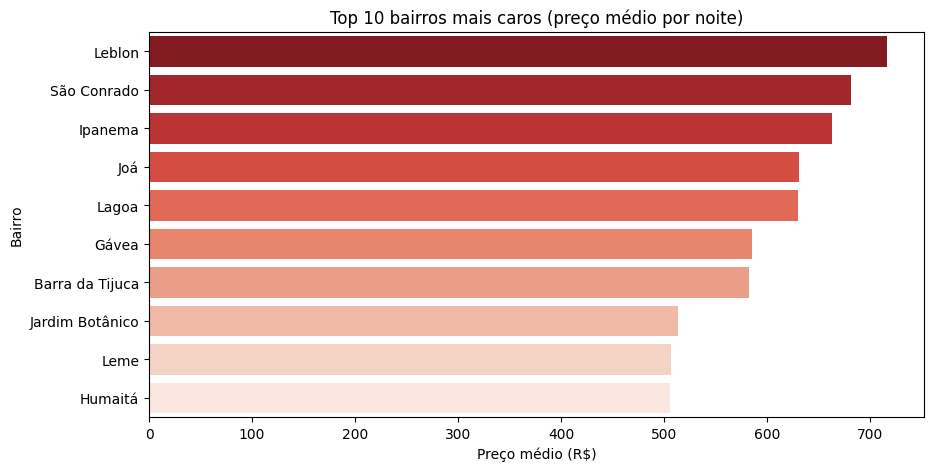

In [526]:
# Gráfico dos 10 bairros mais caros
plt.figure(figsize=(10, 5))
sns.barplot(x=caros.values, y=caros.index, hue=caros.index, palette='Reds_r', legend=False)
plt.title('Top 10 bairros mais caros (preço médio por noite)')
plt.xlabel('Preço médio (R$)')
plt.ylabel('Bairro')
plt.show()

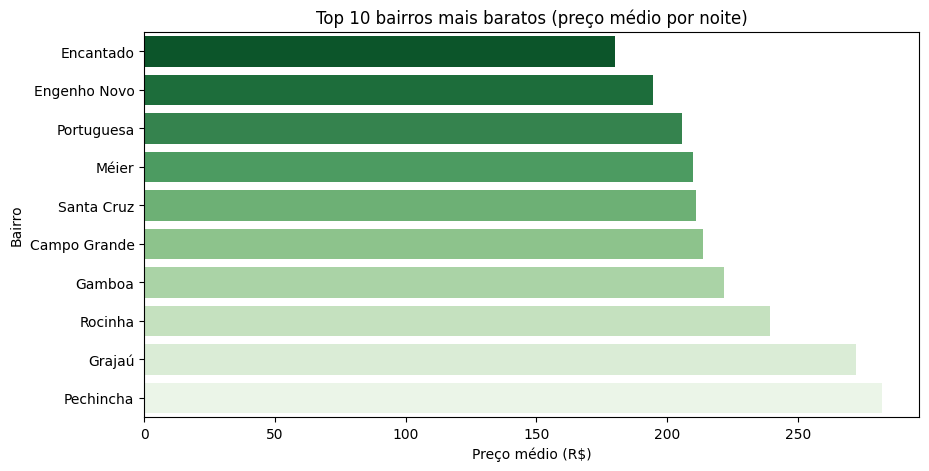

In [527]:
# Gráfico dos 10 bairros mais baratos
plt.figure(figsize=(10, 5))
sns.barplot(x=baratos.values, y=baratos.index, hue=baratos.index, palette='Greens_r', legend=False)
plt.title('Top 10 bairros mais baratos (preço médio por noite)')
plt.xlabel('Preço médio (R$)')
plt.ylabel('Bairro')
plt.show()

**Leitura dos gráficos:** os bairros mais caros ficam na Zona Sul e na Barra. O Leblon lidera com média de R$ 716 por noite, quase 4 vezes o Encantado, o mais barato (R$ 180). Os mais baratos ficam principalmente na Zona Norte e na Zona Oeste.

### P2. Preço por tipo de acomodação nos bairros com mais anúncios

In [528]:
# Os 10 bairros com mais anúncios
top_bairros = df['bairro'].value_counts().head(10).index

# Preço médio de cada tipo de acomodação (linhas: bairros, colunas: tipos)
df[df['bairro'].isin(top_bairros)].pivot_table(index='bairro', columns='tipo_quarto', values='preco', aggfunc='mean').round(2)

tipo_quarto,Entire home/apt,Hotel room,Private room,Shared room
bairro,,,,
Barra da Tijuca,612.07,584.50,382.49,410.50
Botafogo,462.86,302.83,306.42,106.36
Centro,311.58,NaN,222.50,120.74
Copacabana,506.35,324.33,339.41,131.44
Flamengo,467.55,NaN,351.95,90.00
Ipanema,700.35,NaN,394.34,180.67
Jacarepaguá,459.60,NaN,421.48,299.29
Leblon,737.53,NaN,426.16,315.00
Recreio dos Bandeirantes,450.29,NaN,349.67,120.50


### P3. Superhosts cobram mais e têm avaliações melhores?

In [529]:
# Comparação de preço médio e nota geral média entre Superhosts e não-Superhosts
df.groupby('anfitriao_superhost')[['preco', 'nota_geral']].mean().round(2)

,preco,nota_geral
anfitriao_superhost,,
False,466.48,4.75
True,461.77,4.89


### P4. Comodidades mais comuns e o efeito da piscina no preço

In [530]:
# As 20 comodidades mais comuns (uma linha por comodidade no df_explodido)
df_explodido['comodidades'].value_counts().head(20)

,count
comodidades,
Wifi,33225
Kitchen,32835
Hot water,27590
Bed linens,25601
Dishes and silverware,25560
Cooking basics,24074
Hangers,23960
Iron,23822
TV,23359


In [531]:
# Os nomes vêm com variações ("Pool", "Shared outdoor pool"...), então buscamos 'pool' no texto,
# ignorando falsos positivos: "Pool table" (sinuca), "Pool view" (só vista) e "Whirlpool" (marca de eletrodoméstico).
piscina = df_explodido['comodidades'].str.contains('pool', case=False, na=False) & \
          ~df_explodido['comodidades'].str.contains('table|view|whirlpool', case=False, na=False)

# O df_explodido serve para ACHAR quem tem piscina; a marcação vai no df (1 linha por anúncio)
df['tem_piscina'] = df['id'].isin(df_explodido.loc[piscina, 'id'])

df['tem_piscina'].value_counts()

/tmp/ipykernel_4548/2500800146.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['tem_piscina'] = df['id'].isin(df_explodido.loc[piscina, 'id'])


,count
tem_piscina,
False,28728
True,7450


In [532]:
# Preço médio de anúncios com e sem piscina
df.groupby('tem_piscina')['preco'].mean().round(2)

,preco
tem_piscina,
False,448.08
True,527.72


### P5. Quantos anfitriões entraram no Airbnb a cada ano?
Nesta extração a coluna `host_since` veio vazia, então o ano de entrada foi estimado pela data da primeira avaliação. Considera os anfitriões que têm anúncios ativos na data da extração.

In [533]:
df['ano'] = df['anfitriao_desde'].dt.strftime('%Y') # Criamos a coluna ano para identificar a quantidade de anfitriões por ano

/tmp/ipykernel_4548/983634953.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['ano'] = df['anfitriao_desde'].dt.strftime('%Y') # Criamos a coluna ano para identificar a quantidade de anfitriões por ano


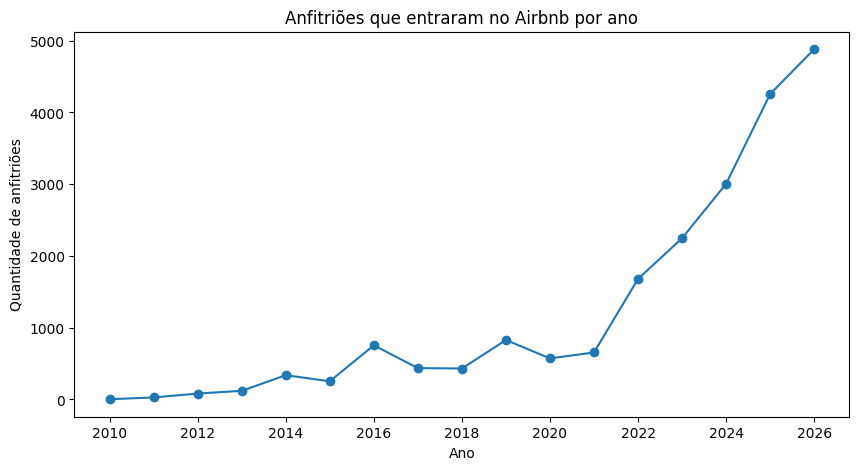

,count
ano,
2010,3
2011,28
2012,82
2013,120
2014,338
2015,253
2016,754
2017,437
2018,431


In [534]:
# Um anfitrião pode ter vários anúncios: drop_duplicates deixa cada anfitrião uma vez só
anfitrioes_por_ano = df.drop_duplicates(subset='anfitriao_id')['ano'].value_counts().sort_index()

anfitrioes_por_ano.plot(figsize=(10, 5), marker='o', title='Anfitriões que entraram no Airbnb por ano')
plt.xlabel('Ano')
plt.ylabel('Quantidade de anfitriões')
plt.show()

anfitrioes_por_ano

### P6. Diária média em dólar
Cotação do dólar pela API do Banco Central (série 1, dólar comercial).

In [535]:
URL_DOLAR = 'https://api.bcb.gov.br/dados/serie/bcdata.sgs.1/dados/ultimos/1?formato=json'

In [536]:
# Requisição para a API do Banco Central para obter a cotação atual do dólar
response = requests.get(URL_DOLAR)
dados_dolar = response.json()

# Extraindo o valor da taxa de venda do dólar comercial
cotacao_dolar = float(dados_dolar[0]['valor'])

# Calculando a média em dólar
media = df['preco'].mean()
diaria_dol = media / cotacao_dolar

print(f"Cotação do Dólar obtida: R$ {cotacao_dolar:.2f}")
print(f"Diária média em Dólar: $ {diaria_dol:.2f}")

Cotação do Dólar obtida: R$ 5.33
Diária média em Dólar: $ 87.05


**Leitura:** a diária média no Rio é de R$ 463,98, o que equivale a US$ 87,05 com o dólar a R$ 5,33 no dia da consulta.

## 7. Exportação

Salva a base tratada em CSV e em um arquivo de banco de dados SQLite.

In [537]:
# Exportando os dados tratados para formato CSV
df.to_csv('listings_rio_tratado.csv', index=False)

In [ ]:
# Salvando a base tratada em um arquivo SQLite (tabela 'listings')
import sqlite3

conexao = sqlite3.connect('airbnb_rio.db')

# O SQLite não guarda listas: salvamos as comodidades como texto
df_sql = df.copy()
df_sql['comodidades'] = df_sql['comodidades'].astype(str)
df_sql.to_sql('listings', conexao, index=False, if_exists='replace')

conexao.close()

## 8. Conclusões

A base tinha 48.247 anúncios. Depois do tratamento ficaram 36.178: saíram 9.058 anúncios sem nenhuma avaliação, 2 sem notas e 3.009 com preço fora do padrão (outliers).

| Pergunta | Resposta |
| --- | --- |
| P1 | O Leblon é o bairro mais caro (R$ 716 por noite em média), seguido de São Conrado e Ipanema. O mais barato é o Encantado (R$ 180). A diferença entre os dois é de quase 4 vezes. |
| P2 | O apartamento inteiro é sempre o tipo mais caro. No Leblon custa R$ 738 e em Ipanema R$ 700. No Leblon e em Ipanema o quarto privativo custa menos de 60% do apartamento inteiro; em Jacarepaguá os dois têm preço parecido (92%). |
| P3 | Superhosts não cobram mais: o preço médio é praticamente igual (R$ 462 contra R$ 466). Mas eles são mais bem avaliados, com nota média de 4,89 contra 4,75. |
| P4 | Wi-Fi (92% dos anúncios) e cozinha (91%) são as comodidades mais comuns; ar-condicionado aparece em 63%. Anúncios com piscina custam em média R$ 528, cerca de 18% a mais que os sem piscina (R$ 448). |
| P5 | A entrada de novos anfitriões cresceu muito a partir de 2022: foram 655 em 2021, 1.680 em 2022 e 4.256 em 2025. Em 2026 já são 4.881 até setembro. |
| P6 | A diária média é de R$ 463,98, o que equivale a US$ 87,05 (dólar a R$ 5,33). |

**Limitações:**
- O preço analisado é o anunciado, não o valor pago pelo hóspede.
- Os dados são de uma única extração (22/09/2026).
- 3.131 anúncios da base final não informam preço; eles ficam fora das médias.
- Nesta extração, a data de entrada do anfitrião, as taxas de resposta e aceitação e a reserva imediata vieram vazias. Por isso o ano de entrada (P5) foi estimado pela primeira avaliação.
- A diferença de preço da piscina pode ter relação com outros fatores, como o bairro e o tamanho do imóvel. A análise não separa esses efeitos.

**Próximos passos:** comparar o Rio com outras cidades do Brasil e analisar como o preço muda ao longo do ano.